In [2]:
import pandas as pd

df = pd.read_csv('online_retail.csv')

df.head(20)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
5,489434,22064,PINK DOUGHNUT TRINKET POT,24,2009-12-01 07:45:00,1.65,13085.0,United Kingdom
6,489434,21871,SAVE THE PLANET MUG,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
7,489434,21523,FANCY FONT HOME SWEET HOME DOORMAT,10,2009-12-01 07:45:00,5.95,13085.0,United Kingdom
8,489435,22350,CAT BOWL,12,2009-12-01 07:46:00,2.55,13085.0,United Kingdom
9,489435,22349,"DOG BOWL , CHASING BALL DESIGN",12,2009-12-01 07:46:00,3.75,13085.0,United Kingdom


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1067371 non-null  str    
 1   StockCode    1067371 non-null  str    
 2   Description  1062989 non-null  str    
 3   Quantity     1067371 non-null  int64  
 4   InvoiceDate  1067371 non-null  str    
 5   Price        1067371 non-null  float64
 6   Customer ID  824364 non-null   float64
 7   Country      1067371 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 136.6 MB


## Investigating Cancelled orders

So I know the approach. Do the invoice numbers correspond, are they separate? Will inform how cancellation rate is approached

In [4]:
cancelled = df[df['Quantity'] < 0]
cancelled.head(20)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
183,C489449,21871,SAVE THE PLANET MUG,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,2009-12-01 10:33:00,0.85,16321.0,Australia
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,2009-12-01 10:44:00,4.25,17592.0,United Kingdom


In [5]:
df[df['Invoice'] == '489459']

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country


In [6]:
df["Invoice"] = df["Invoice"].astype(str)
c = df[df["Invoice"].str.startswith("C")]
pos = df[~df["Invoice"].str.startswith("C") & (df["Quantity"] > 0)]

# 1. Is there a normal invoice with the same number minus the C?
print(c["Invoice"].str[1:].isin(pos["Invoice"]).mean())

# 2. Did that customer ever buy that item?
c2 = c.dropna(subset=["Customer ID"])
keys = set(zip(pos["Customer ID"], pos["StockCode"]))
print(pd.Series(list(zip(c2["Customer ID"], c2["StockCode"]))).map(lambda k: k in keys).mean())

0.0
0.920827998292787


## Cleaning
### Date to dateime

In [7]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"].str.strip()).dt.date

In [8]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01,1.25,13085.0,United Kingdom


### Customer ID to String

In [9]:
df["Customer ID"] = df["Customer ID"].astype("Int64").astype("string")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1067371 non-null  str    
 1   StockCode    1067371 non-null  str    
 2   Description  1062989 non-null  str    
 3   Quantity     1067371 non-null  int64  
 4   InvoiceDate  1067371 non-null  object 
 5   Price        1067371 non-null  float64
 6   Customer ID  824364 non-null   string 
 7   Country      1067371 non-null  str    
dtypes: float64(1), int64(1), object(1), str(4), string(1)
memory usage: 121.4+ MB


### Dealing with Missing Customer ID

Will create a separate df with these excluded for customer segmentation, but will do it later

Leaving them present as missing customer ID doesn't necessarily mean any other invalidity and, unless I'm specifically looking at customers, there's no need to exclude them

## df_all_id is the created table... need to rerun it later!!

In [10]:
no_id = df[df['Customer ID'].isna()]
no_id

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01,0.00,<NA>,United Kingdom
283,489463,71477,short,-240,2009-12-01,0.00,<NA>,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01,0.00,<NA>,United Kingdom
470,489521,21646,NaN,-50,2009-12-01,0.00,<NA>,United Kingdom
577,489525,85226C,BLUE PULL BACK RACING CAR,1,2009-12-01,0.55,<NA>,United Kingdom
...,...,...,...,...,...,...,...,...
1066997,581498,85099B,JUMBO BAG RED RETROSPOT,5,2011-12-09,4.13,<NA>,United Kingdom
1066998,581498,85099C,JUMBO BAG BAROQUE BLACK WHITE,4,2011-12-09,4.13,<NA>,United Kingdom
1066999,581498,85150,LADIES & GENTLEMEN METAL SIGN,1,2011-12-09,4.96,<NA>,United Kingdom
1067000,581498,85174,S/4 CACTI CANDLES,1,2011-12-09,10.79,<NA>,United Kingdom


In [11]:
df_all_id = df.dropna(subset=["Customer ID"]).copy()
df_all_id.info()

<class 'pandas.DataFrame'>
Index: 824364 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   Invoice      824364 non-null  str    
 1   StockCode    824364 non-null  str    
 2   Description  824364 non-null  str    
 3   Quantity     824364 non-null  int64  
 4   InvoiceDate  824364 non-null  object 
 5   Price        824364 non-null  float64
 6   Customer ID  824364 non-null  string 
 7   Country      824364 non-null  str    
dtypes: float64(1), int64(1), object(1), str(4), string(1)
memory usage: 101.2+ MB


### Missing Product descriptions

Turns out, they're all invalid. So drop the lot.

In [12]:
# 1. Treat blank descriptions as missing
df["Description"] = df["Description"].replace(r"^\s*$", pd.NA, regex=True)

# 2. Check what the missing ones look like
miss = df["Description"].isna()
print(miss.sum(), (df.loc[miss, "Price"] == 0).mean(), df.loc[miss, "Customer ID"].isna().mean())

# 3. Fill from other rows with the same StockCode (most common description)
lookup = (df.dropna(subset=["Description"])
            .groupby("StockCode")["Description"]
            .agg(lambda s: s.mode().iloc[0]))
df["Description"] = df["Description"].fillna(df["StockCode"].map(lookup))

# 4. Drop what's still missing
df = df.dropna(subset=["Description"])

4382 1.0 1.0


In [13]:
df = df.dropna(subset=["Description"])
df.info()

<class 'pandas.DataFrame'>
Index: 1067008 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1067008 non-null  str    
 1   StockCode    1067008 non-null  str    
 2   Description  1067008 non-null  str    
 3   Quantity     1067008 non-null  int64  
 4   InvoiceDate  1067008 non-null  object 
 5   Price        1067008 non-null  float64
 6   Customer ID  824364 non-null   string 
 7   Country      1067008 non-null  str    
dtypes: float64(1), int64(1), object(1), str(4), string(1)
memory usage: 130.0+ MB


### Invoice shenanigans

Invoices starting with A are the bad debt adjustments

In [14]:
df["Invoice"] = df["Invoice"].astype(str)
a = df[df["Invoice"].str.startswith("A")]
print(len(a))
print(a["Description"].value_counts())
print(a[["Price", "Quantity"]].describe())
print(a["Customer ID"].isna().mean())

6
Description
Adjust bad debt    6
Name: count, dtype: int64
              Price  Quantity
count      6.000000       6.0
mean  -24602.346667       1.0
std    24746.038289       0.0
min   -53594.360000       1.0
25%   -42755.310000       1.0
50%   -24993.965000       1.0
75%   -11062.060000       1.0
max    11062.060000       1.0
1.0


In [15]:
df = df[~df["Invoice"].str.startswith("A")].copy()

In [16]:
df["Invoice"] = df["Invoice"].astype(str)
a = df[df["Invoice"].str.startswith("A")]
print(len(a))
print(a["Description"].value_counts())
print(a[["Price", "Quantity"]].describe())
print(a["Customer ID"].isna().mean())

0
Series([], Name: count, dtype: int64)
       Price  Quantity
count    0.0       0.0
mean     NaN       NaN
std      NaN       NaN
min      NaN       NaN
25%      NaN       NaN
50%      NaN       NaN
75%      NaN       NaN
max      NaN       NaN
nan


### Product Codes

These should start with 5 digits, I think letter can come after, but not before

Some seem to. Have removed everything from the df with an invalid description accompanying it

In [17]:
USC = df['StockCode'].unique().value_counts()
len(USC)

4949

In [18]:
USC

85048     1
79323P    1
79323W    1
22041     1
21232     1
         ..
23562     1
23561     1
23609     1
23617     1
23843     1
Name: count, Length: 4949, dtype: int64

In [19]:
inv_sc = df[~df['StockCode'].astype('str').str.match(r'^\d{5}')] # For the bad items only
inv_sc.info()
inv_sc.head()

<class 'pandas.DataFrame'>
Index: 6065 entries, 89 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Invoice      6065 non-null   str    
 1   StockCode    6065 non-null   str    
 2   Description  6065 non-null   str    
 3   Quantity     6065 non-null   int64  
 4   InvoiceDate  6065 non-null   object 
 5   Price        6065 non-null   float64
 6   Customer ID  3738 non-null   string 
 7   Country      6065 non-null   str    
dtypes: float64(1), int64(1), object(1), str(4), string(1)
memory usage: 628.4+ KB


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
89,489439,POST,POSTAGE,3,2009-12-01,18.0,12682,France
126,489444,POST,POSTAGE,1,2009-12-01,141.0,12636,USA
173,489447,POST,POSTAGE,1,2009-12-01,130.0,12362,Belgium
625,489526,POST,POSTAGE,6,2009-12-01,18.0,12533,Germany
735,C489535,D,Discount,-1,2009-12-01,9.0,15299,United Kingdom


In [20]:
inv_sc['Description'].isna().value_counts()

Description
False    6065
Name: count, dtype: int64

In [21]:
inv_sc['Description'].unique()

<ArrowStringArray>
[                            'POSTAGE',                            'Discount',
                    'MISO PRETTY  GUM',                   'DOGS NIGHT COLLAR',
                      'DOTCOM POSTAGE',                              'Manual',
          'HAYNES CAMPER SHOULDER BAG',        'SUNJAR LED NIGHT NIGHT LIGHT',
                            'CARRIAGE',                       ' Bank Charges',
                 'BOXED GLASS ASHTRAY',             'This is a test product.',
  'Dotcomgiftshop Gift Voucher £80.00',              'CAT CAMOUFLAGUE COLLAR',
  'Dotcomgiftshop Gift Voucher £20.00',             'HANDZ-OFF CAR FRESHENER',
  'Dotcomgiftshop Gift Voucher £10.00',  'Dotcomgiftshop Gift Voucher £50.00',
             'NAVY CUDDLES DOG HOODIE',  'Dotcomgiftshop Gift Voucher £30.00',
          'PADS TO MATCH ALL CUSHIONS', 'Adjustment by john on 26/01/2010 16',
 'Adjustment by john on 26/01/2010 17',  'Dotcomgiftshop Gift Voucher £40.00',
  'Dotcomgiftshop Gift Voucher £7

In [22]:
df[df['Description'] == 'HAYNES CAMPER SHOULDER BAG']

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
8371,490074,DCGS0004,HAYNES CAMPER SHOULDER BAG,1,2009-12-03,17.35,<NA>,United Kingdom
98951,498699,DCGS0004,HAYNES CAMPER SHOULDER BAG,-2,2010-02-22,0.00,<NA>,United Kingdom
164723,504935,DCGS0004,HAYNES CAMPER SHOULDER BAG,1,2010-04-19,16.98,<NA>,United Kingdom
401083,527789,DCGS0004,HAYNES CAMPER SHOULDER BAG,1,2010-10-19,16.98,<NA>,United Kingdom
696244,551340,DCGS0004,HAYNES CAMPER SHOULDER BAG,1,2011-04-27,16.63,<NA>,United Kingdom


In [23]:
df[df['Description'] == 'CARRIAGE']

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
9292,490127,C2,CARRIAGE,1,2009-12-03,50.0,14156,EIRE
14481,490541,C2,CARRIAGE,1,2009-12-07,50.0,<NA>,EIRE
14502,490542,C2,CARRIAGE,1,2009-12-07,50.0,14911,EIRE
19541,490998,C2,CARRIAGE,1,2009-12-08,50.0,16253,United Kingdom
22803,491160,C2,CARRIAGE,1,2009-12-10,50.0,14911,EIRE
...,...,...,...,...,...,...,...,...
1040462,579768,C2,CARRIAGE,1,2011-11-30,50.0,14911,EIRE
1041945,579910,C2,CARRIAGE,1,2011-12-01,50.0,14911,EIRE
1044315,580124,C2,CARRIAGE,1,2011-12-01,50.0,<NA>,EIRE
1044366,580127,C2,CARRIAGE,1,2011-12-01,50.0,14911,EIRE


In [24]:
df[df['Description'] == 'SAMPLES']

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
114061,C500305,S,SAMPLES,-1,2010-03-07,73.80,<NA>,United Kingdom
114083,C500309,S,SAMPLES,-1,2010-03-07,32.03,<NA>,United Kingdom
133558,C502083,S,SAMPLES,-1,2010-03-22,170.37,<NA>,United Kingdom
133582,C502088,S,SAMPLES,-1,2010-03-22,259.59,<NA>,United Kingdom
136253,C502438,S,SAMPLES,-1,2010-03-24,605.18,<NA>,United Kingdom
...,...,...,...,...,...,...,...,...
939608,C572347,S,SAMPLES,-1,2011-10-24,33.05,<NA>,United Kingdom
945127,572849,S,SAMPLES,1,2011-10-26,33.05,<NA>,United Kingdom
1006422,C577330,S,SAMPLES,-1,2011-11-18,2.89,<NA>,United Kingdom
1006423,C577330,S,SAMPLES,-1,2011-11-18,75.00,<NA>,United Kingdom


In [25]:
invalid_descriptions = ['POSTAGE','DOTCOM POSTAGE','CARRIAGE','Dotcomgiftshop Gift Voucher £80.00','Dotcomgiftshop Gift Voucher £20.00',\
                        'Dotcomgiftshop Gift Voucher £10.00','Adjustment by john on 26/01/2010 17','Dotcomgiftshop Gift Voucher £70.00','Bank Charges',\
                        'Adjustment by Peter on 24/05/2010 1','UPDATE','to push order througha s stock was ','CRUK Commission','Discount','Manual',\
                        ' Bank Charges','This is a test product.','Dotcomgiftshop Gift Voucher £50.00','Dotcomgiftshop Gift Voucher £30.00',\
                        'Adjustment by john on 26/01/2010 16','Dotcomgiftshop Gift Voucher £40.00','SAMPLES','Adjustment by Peter on Jun 25 2010 ',\
                        'AMAZON FEE','ebay']
                        

In [26]:
df = df[~df['Description'].isin(invalid_descriptions)]
df.info()

<class 'pandas.DataFrame'>
Index: 1061096 entries, 0 to 1067369
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1061096 non-null  str    
 1   StockCode    1061096 non-null  str    
 2   Description  1061096 non-null  str    
 3   Quantity     1061096 non-null  int64  
 4   InvoiceDate  1061096 non-null  object 
 5   Price        1061096 non-null  float64
 6   Customer ID  820647 non-null   string 
 7   Country      1061096 non-null  str    
dtypes: float64(1), int64(1), object(1), str(4), string(1)
memory usage: 129.4+ MB


In [27]:
inv_sc_update = df[~df['StockCode'].astype('str').str.match(r'^\d{5}')]

In [28]:
inv_sc_update['Description'].unique()

<ArrowStringArray>
[                'MISO PRETTY  GUM',                'DOGS NIGHT COLLAR',
       'HAYNES CAMPER SHOULDER BAG',     'SUNJAR LED NIGHT NIGHT LIGHT',
              'BOXED GLASS ASHTRAY',           'CAT CAMOUFLAGUE COLLAR',
          'HANDZ-OFF CAR FRESHENER',          'NAVY CUDDLES DOG HOODIE',
       'PADS TO MATCH ALL CUSHIONS',                  'GIRLS PARTY BAG',
          'ROAD-RAGE CAR FRESHENER',               'KEY-RING CORKSCREW',
                   'BOYS PARTY BAG',            'OOH LA LA DOGS COLLAR',
            'CAMOUFLAGE DOG COLLAR',             'CAMOUFLAGUE DOG LEAD',
 'HAYNES MINI-COOPER PLAYING CARDS',                           'update',
           'KID'S CHALKBOARD/EASEL']
Length: 19, dtype: str

In [29]:
inv_sc_update

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
2377,489597,DCGS0058,MISO PRETTY GUM,1,2009-12-01,0.830,<NA>,United Kingdom
2378,489597,DCGS0068,DOGS NIGHT COLLAR,1,2009-12-01,8.650,<NA>,United Kingdom
8371,490074,DCGS0004,HAYNES CAMPER SHOULDER BAG,1,2009-12-03,17.350,<NA>,United Kingdom
8372,490074,DCGS0058,MISO PRETTY GUM,1,2009-12-03,0.830,<NA>,United Kingdom
8373,490074,DCGS0076,SUNJAR LED NIGHT NIGHT LIGHT,1,2009-12-03,16.480,<NA>,United Kingdom
...,...,...,...,...,...,...,...,...
885332,568200,PADS,PADS TO MATCH ALL CUSHIONS,1,2011-09-25,0.001,16198,United Kingdom
891427,568716,DCGSSBOY,BOYS PARTY BAG,2,2011-09-28,3.290,<NA>,United Kingdom
933664,571931,DCGSSGIRL,GIRLS PARTY BAG,1,2011-10-19,3.290,<NA>,United Kingdom
1000063,576840,DCGSSGIRL,GIRLS PARTY BAG,1,2011-11-16,3.290,<NA>,United Kingdom


### Negative pricing and quantity

All returns have negative quantity? Yes

In [30]:
df[df['Quantity'] < 0]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01,2.95,16321,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01,1.65,16321,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01,4.25,16321,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01,2.10,16321,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01,2.95,16321,Australia
...,...,...,...,...,...,...,...,...
1065909,C581490,22178,VICTORIAN GLASS HANGING T-LIGHT,-12,2011-12-09,1.95,14397,United Kingdom
1065910,C581490,23144,ZINC T-LIGHT HOLDER STARS SMALL,-11,2011-12-09,0.83,14397,United Kingdom
1067176,C581568,21258,VICTORIAN SEWING BOX LARGE,-5,2011-12-09,10.95,15311,United Kingdom
1067177,C581569,84978,HANGING HEART JAR T-LIGHT HOLDER,-1,2011-12-09,1.25,17315,United Kingdom


In [31]:
df[(df['Invoice'].astype('str').str.startswith('C')) & (df['Quantity'] > 0)]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country


In [32]:
df[(~df['Invoice'].astype('str').str.startswith('C')) & (df['Quantity'] < 0)]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01,0.0,<NA>,United Kingdom
283,489463,71477,short,-240,2009-12-01,0.0,<NA>,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01,0.0,<NA>,United Kingdom
3114,489655,20683,RAIN GIRL CHILDS UMBRELLA,-44,2009-12-01,0.0,<NA>,United Kingdom
3162,489660,35956,lost,-1043,2009-12-01,0.0,<NA>,United Kingdom
...,...,...,...,...,...,...,...,...
1060794,581210,23395,check,-26,2011-12-07,0.0,<NA>,United Kingdom
1060796,581212,22578,lost,-1050,2011-12-07,0.0,<NA>,United Kingdom
1060797,581213,22576,check,-30,2011-12-07,0.0,<NA>,United Kingdom
1062371,581226,23090,missing,-338,2011-12-08,0.0,<NA>,United Kingdom


## Negative quantity issues / Removing price = 0

From the above, lots of entries with neg quant, but all seem to have price = 0. Time to check price = 0 or negative

In [33]:
df[df['Price']<=0]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01,0.0,<NA>,United Kingdom
283,489463,71477,short,-240,2009-12-01,0.0,<NA>,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01,0.0,<NA>,United Kingdom
3114,489655,20683,RAIN GIRL CHILDS UMBRELLA,-44,2009-12-01,0.0,<NA>,United Kingdom
3161,489659,21350,GINGHAM HEART WREATH,230,2009-12-01,0.0,<NA>,United Kingdom
...,...,...,...,...,...,...,...,...
1062442,581234,72817,SET OF 2 CHRISTMAS DECOUPAGE CANDLE,27,2011-12-08,0.0,<NA>,United Kingdom
1063965,581406,46000M,POLYESTER FILLER PAD 45x45cm,240,2011-12-08,0.0,<NA>,United Kingdom
1063966,581406,46000S,POLYESTER FILLER PAD 40x40cm,300,2011-12-08,0.0,<NA>,United Kingdom
1064015,581408,85175,CACTI T-LIGHT CANDLES,20,2011-12-08,0.0,<NA>,United Kingdom


In [34]:
df[(df['Price'] <= 0) & (df['Customer ID'].notna())]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
4674,489825,22076,6 RIBBONS EMPIRE,12,2009-12-02,0.0,16126,United Kingdom
6781,489998,48185,DOOR MAT FAIRY CAKE,2,2009-12-03,0.0,15658,United Kingdom
18738,490961,22065,CHRISTMAS PUDDING TRINKET POT,1,2009-12-08,0.0,14108,United Kingdom
18739,490961,22142,CHRISTMAS CRAFT WHITE FAIRY,12,2009-12-08,0.0,14108,United Kingdom
32916,492079,85042,ANTIQUE LILY FAIRY LIGHTS,8,2009-12-15,0.0,15070,United Kingdom
...,...,...,...,...,...,...,...,...
979924,575579,22437,SET OF 9 BLACK SKULL BALLOONS,20,2011-11-10,0.0,13081,United Kingdom
979925,575579,22089,PAPER BUNTING VINTAGE PAISLEY,24,2011-11-10,0.0,13081,United Kingdom
1004540,577129,22464,HANGING METAL HEART LANTERN,4,2011-11-17,0.0,15602,United Kingdom
1006110,577314,23407,SET OF 2 TRAYS HOME SWEET HOME,2,2011-11-18,0.0,12444,Norway


### Entries where price is zero but all other fields are valid

Will have to be dropped as we cannot guess what the price is. Would be possible to pull it from other items, but it is only 62 rows

In [35]:
df = df[df['Price'] > 0]
df.info()

<class 'pandas.DataFrame'>
Index: 1055307 entries, 0 to 1067369
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1055307 non-null  str    
 1   StockCode    1055307 non-null  str    
 2   Description  1055307 non-null  str    
 3   Quantity     1055307 non-null  int64  
 4   InvoiceDate  1055307 non-null  object 
 5   Price        1055307 non-null  float64
 6   Customer ID  820585 non-null   string 
 7   Country      1055307 non-null  str    
dtypes: float64(1), int64(1), object(1), str(4), string(1)
memory usage: 128.7+ MB


## Rerunning missing customer ID

In [36]:
no_id = df[df['Customer ID'].isna()]
no_id

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
577,489525,85226C,BLUE PULL BACK RACING CAR,1,2009-12-01,0.55,<NA>,United Kingdom
578,489525,85227,SET/6 3D KIT CARDS FOR KIDS,1,2009-12-01,0.85,<NA>,United Kingdom
1055,489548,22271,FELTCRAFT DOLL ROSIE,1,2009-12-01,2.95,<NA>,United Kingdom
1056,489548,22254,FELT TOADSTOOL LARGE,12,2009-12-01,1.25,<NA>,United Kingdom
1057,489548,22273,FELTCRAFT DOLL MOLLY,3,2009-12-01,2.95,<NA>,United Kingdom
...,...,...,...,...,...,...,...,...
1066996,581498,85049e,SCANDINAVIAN REDS RIBBONS,4,2011-12-09,3.29,<NA>,United Kingdom
1066997,581498,85099B,JUMBO BAG RED RETROSPOT,5,2011-12-09,4.13,<NA>,United Kingdom
1066998,581498,85099C,JUMBO BAG BAROQUE BLACK WHITE,4,2011-12-09,4.13,<NA>,United Kingdom
1066999,581498,85150,LADIES & GENTLEMEN METAL SIGN,1,2011-12-09,4.96,<NA>,United Kingdom


In [37]:
df_all_id = df.dropna(subset=["Customer ID"]).copy()
df_all_id.info()

<class 'pandas.DataFrame'>
Index: 820585 entries, 0 to 1067369
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   Invoice      820585 non-null  str    
 1   StockCode    820585 non-null  str    
 2   Description  820585 non-null  str    
 3   Quantity     820585 non-null  int64  
 4   InvoiceDate  820585 non-null  object 
 5   Price        820585 non-null  float64
 6   Customer ID  820585 non-null  string 
 7   Country      820585 non-null  str    
dtypes: float64(1), int64(1), object(1), str(4), string(1)
memory usage: 100.8+ MB


## Exporting all ID only for later... may need to redo

In [38]:
df_all_id.to_csv('cleaned_all_id.csv', index=False)

# Determining low-selling item threshold

1. Separate dfs; totals add up to whole df
2. Calculate units sold for each item; will require df creation with Stock Code.unique

In [39]:
df_sold = df[~df['Invoice'].astype(str).str.startswith('C')]
df_cancelled = df[df['Invoice'].astype(str).str.startswith('C')]
df_sold.info()
df_cancelled.info()

<class 'pandas.DataFrame'>
Index: 1037021 entries, 0 to 1067369
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1037021 non-null  str    
 1   StockCode    1037021 non-null  str    
 2   Description  1037021 non-null  str    
 3   Quantity     1037021 non-null  int64  
 4   InvoiceDate  1037021 non-null  object 
 5   Price        1037021 non-null  float64
 6   Customer ID  802651 non-null   string 
 7   Country      1037021 non-null  str    
dtypes: float64(1), int64(1), object(1), str(4), string(1)
memory usage: 126.4+ MB
<class 'pandas.DataFrame'>
Index: 18286 entries, 178 to 1067178
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Invoice      18286 non-null  str    
 1   StockCode    18286 non-null  str    
 2   Description  18286 non-null  str    
 3   Quantity     18286 non-null  int64  
 4   InvoiceDate  18286 non-null 

In [40]:
df_sold.to_csv('cleaned_df_sold.csv', index=False)

In [41]:
items = pd.DataFrame({"Description": df.groupby("StockCode")["Description"].first()})
items["units_sold"] = df_sold.groupby("StockCode")["Quantity"].sum()
items["units_cancelled"] = -df_cancelled.groupby("StockCode")["Quantity"].sum()
items = items.fillna({"units_sold": 0, "units_cancelled": 0})

overall_rate = items["units_cancelled"].sum() / items["units_sold"].sum()
threshold = 10 / overall_rate

print(overall_rate, threshold)
print((items["units_sold"] < threshold).sum(), len(items))
print(items["units_sold"].describe())

0.042261238616811796 236.62344804115455
1729 4910
count      4910.000000
mean       2322.336253
std        5914.517053
min           0.000000
25%         102.000000
50%         590.000000
75%        2103.750000
max      110138.000000
Name: units_sold, dtype: float64


### Threshold determination

4.2% is cancellation rate in terms of units
237 is about the threshold where you'd expect 10 cancellations

This would exclude 1,729 items out of 4910. (c.35%)

BUT only 1.1% of units sold and 0.7% of cancelled units, so it's a decent threshold.

In [42]:
below = items["units_sold"] < threshold
print(items.loc[below, "units_sold"].sum() / items["units_sold"].sum())
print(items.loc[below, "units_cancelled"].sum() / items["units_cancelled"].sum())

0.01056471768763652
0.0067567146927417195


In [43]:
items_f = items[items["units_sold"] >= threshold].copy()
items_f["cancel_rate"] = items_f["units_cancelled"] / items_f["units_sold"]

print(len(items_f))
print(items_f["cancel_rate"].describe())

3181
count    3181.000000
mean        0.029462
std         0.084523
min         0.000000
25%         0.000414
50%         0.007226
75%         0.021825
max         1.020576
Name: cancel_rate, dtype: float64


In [44]:
items_f.head()

,Description,units_sold,units_cancelled,cancel_rate
StockCode,,,,
10002,INFLATABLE POLITICAL GLOBE,8836.0,1223.0,0.138411
10080,GROOVY CACTUS INFLATABLE,315.0,0.0,0.000000
10120,DOGGY RUBBER,680.0,30.0,0.044118
10123C,HEARTS WRAPPING TAPE,654.0,150.0,0.229358
10123G,ARMY CAMO WRAPPING TAPE,2251.0,1104.0,0.490449


In [47]:
items_f.sort_values('units_cancelled', ascending=False)

,Description,units_sold,units_cancelled,cancel_rate
StockCode,,,,
23843,"PAPER CRAFT , LITTLE BIRDIE",80995.0,80995.0,1.000000
23166,MEDIUM CERAMIC TOP STORAGE JAR,78033.0,74494.0,0.954647
84347,ROTATING SILVER ANGELS T-LIGHT HLDR,32525.0,18750.0,0.576480
21088,SET/6 FRUIT SALAD PAPER CUPS,16615.0,7140.0,0.429732
21096,SET/6 FRUIT SALAD PAPER PLATES,15924.0,7008.0,0.440090
...,...,...,...,...
85205B,PINK FELT EASTER RABBIT GARLAND,241.0,0.0,0.000000
85203,HANGING WOOD AND FELT BUTTERFLY,1469.0,0.0,0.000000
85230B,CINNAMON SCENTED VOTIVE CANDLE,2216.0,0.0,0.000000


In [48]:
df["value"] = df["Quantity"] * df["Price"]
items_f["net_revenue"] = items_f.index.map(df.groupby("StockCode")["value"].sum())
items_f.head(20)

,Description,units_sold,units_cancelled,cancel_rate,net_revenue
StockCode,,,,,
10002,INFLATABLE POLITICAL GLOBE,8836.0,1223.0,0.138411,6214.35
10080,GROOVY CACTUS INFLATABLE,315.0,0.0,0.000000,129.29
10120,DOGGY RUBBER,680.0,30.0,0.044118,139.80
10123C,HEARTS WRAPPING TAPE,654.0,150.0,0.229358,244.47
10123G,ARMY CAMO WRAPPING TAPE,2251.0,1104.0,0.490449,99.32
10125,MINI FUNKY DESIGN TAPES,2151.0,0.0,0.000000,1758.20
10133,COLOURING PENCILS BROWN TUBE,3882.0,20.0,0.005152,2394.89
10134,COLOURING PENCILS BROWN TUBE,627.0,10.0,0.015949,711.13
10135,COLOURING PENCILS BROWN TUBE,4273.0,11.0,0.002574,4628.85


## At this point

Have generated a clean table of items with their units sold, units cancelled, cancellation rate, and net revenue

Adding an average price column for logreg later

In [49]:
items_f["avg_price"] = items_f.index.map(df_sold.groupby("StockCode")["Price"].mean())
items_f.head()

,Description,units_sold,units_cancelled,cancel_rate,net_revenue,avg_price
StockCode,,,,,,
10002,INFLATABLE POLITICAL GLOBE,8836.0,1223.0,0.138411,6214.35,0.987801
10080,GROOVY CACTUS INFLATABLE,315.0,0.0,0.000000,129.29,0.505000
10120,DOGGY RUBBER,680.0,30.0,0.044118,139.80,0.238571
10123C,HEARTS WRAPPING TAPE,654.0,150.0,0.229358,244.47,0.782239
10123G,ARMY CAMO WRAPPING TAPE,2251.0,1104.0,0.490449,99.32,0.820588


In [50]:
items_f.head(20)

,Description,units_sold,units_cancelled,cancel_rate,net_revenue,avg_price
StockCode,,,,,,
10002,INFLATABLE POLITICAL GLOBE,8836.0,1223.0,0.138411,6214.35,0.987801
10080,GROOVY CACTUS INFLATABLE,315.0,0.0,0.000000,129.29,0.505000
10120,DOGGY RUBBER,680.0,30.0,0.044118,139.80,0.238571
10123C,HEARTS WRAPPING TAPE,654.0,150.0,0.229358,244.47,0.782239
10123G,ARMY CAMO WRAPPING TAPE,2251.0,1104.0,0.490449,99.32,0.820588
10125,MINI FUNKY DESIGN TAPES,2151.0,0.0,0.000000,1758.20,0.931547
10133,COLOURING PENCILS BROWN TUBE,3882.0,20.0,0.005152,2394.89,0.749030
10134,COLOURING PENCILS BROWN TUBE,627.0,10.0,0.015949,711.13,1.289286
10135,COLOURING PENCILS BROWN TUBE,4273.0,11.0,0.002574,4628.85,1.415605


In [52]:
df[df['Description'] == 'SANDALWOOD FAN']

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,value
6904,490006,15039,SANDALWOOD FAN,10,2009-12-03,0.85,17411,United Kingdom,8.50
18747,490963,15039,SANDALWOOD FAN,1,2009-12-08,1.70,<NA>,United Kingdom,1.70
28660,491803,15039,SANDALWOOD FAN,10,2009-12-14,0.85,16327,United Kingdom,8.50
29577,491893,15039,SANDALWOOD FAN,2,2009-12-14,0.85,16805,United Kingdom,1.70
29797,491951,15039,SANDALWOOD FAN,6,2009-12-14,0.85,13206,United Kingdom,5.10
...,...,...,...,...,...,...,...,...,...
1050369,580611,15039,SANDALWOOD FAN,1,2011-12-05,0.85,12748,United Kingdom,0.85
1054281,580730,15039,SANDALWOOD FAN,40,2011-12-05,1.63,<NA>,United Kingdom,65.20
1057574,580983,15039,SANDALWOOD FAN,3,2011-12-06,1.63,<NA>,United Kingdom,4.89
1063835,581405,15039,SANDALWOOD FAN,1,2011-12-08,0.85,13521,United Kingdom,0.85


In [53]:
items_f_backup = items_f.copy()

In [54]:
total = df_sold.groupby("StockCode")["Quantity"].sum()
q4 = df_sold[pd.to_datetime(df_sold["InvoiceDate"]).dt.month >= 10].groupby("StockCode")["Quantity"].sum()
items_f["xmas_share"] = items_f.index.map((q4 / total).fillna(0))

items_f["typical_qty"] = items_f.index.map(df_sold.groupby("StockCode")["Quantity"].median())

In [55]:
items_f.head(20)

,Description,units_sold,units_cancelled,cancel_rate,net_revenue,avg_price,xmas_share,typical_qty
StockCode,,,,,,,,
10002,INFLATABLE POLITICAL GLOBE,8836.0,1223.0,0.138411,6214.35,0.987801,0.298438,10.0
10080,GROOVY CACTUS INFLATABLE,315.0,0.0,0.000000,129.29,0.505000,0.323810,12.0
10120,DOGGY RUBBER,680.0,30.0,0.044118,139.80,0.238571,0.525000,4.0
10123C,HEARTS WRAPPING TAPE,654.0,150.0,0.229358,244.47,0.782239,0.264526,1.0
10123G,ARMY CAMO WRAPPING TAPE,2251.0,1104.0,0.490449,99.32,0.820588,0.011106,1.0
10125,MINI FUNKY DESIGN TAPES,2151.0,0.0,0.000000,1758.20,0.931547,0.332868,3.0
10133,COLOURING PENCILS BROWN TUBE,3882.0,20.0,0.005152,2394.89,0.749030,0.127512,10.0
10134,COLOURING PENCILS BROWN TUBE,627.0,10.0,0.015949,711.13,1.289286,0.173844,3.0
10135,COLOURING PENCILS BROWN TUBE,4273.0,11.0,0.002574,4628.85,1.415605,0.306108,10.0


In [56]:
items_f = items_f.rename(columns={"typical_qty": "median_qty"})

In [57]:
items_f.to_csv('items_f.csv', index=False)

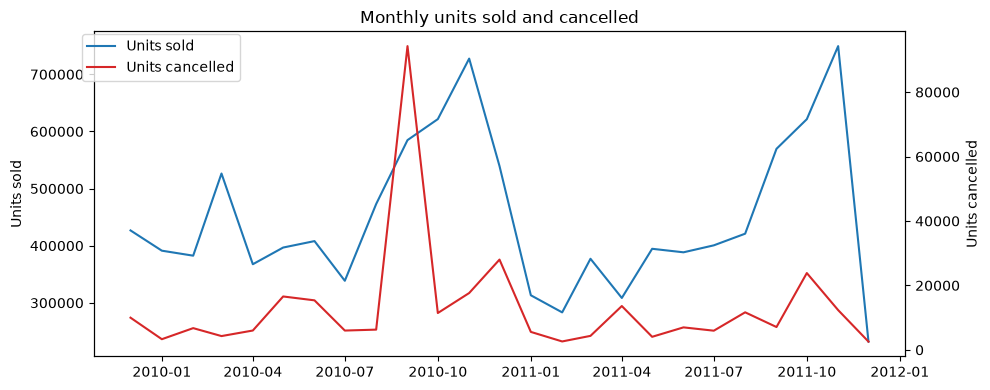

In [58]:
import matplotlib.pyplot as plt

big = ["23843", "23166"]   # the two giant order-and-cancel items

def monthly(d):
    m = pd.to_datetime(d["InvoiceDate"]).dt.to_period("M").dt.to_timestamp()
    return d.groupby(m)["Quantity"].sum()

sold_m = monthly(df_sold[~df_sold["StockCode"].isin(big)])
canc_m = -monthly(df_cancelled[~df_cancelled["StockCode"].isin(big)])

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(sold_m.index, sold_m.values, label="Units sold")
ax.set_ylabel("Units sold")
ax2 = ax.twinx()
ax2.plot(canc_m.index, canc_m.values, color="tab:red", label="Units cancelled")
ax2.set_ylabel("Units cancelled")
fig.legend(loc="upper left", bbox_to_anchor=(0.08, 0.92))
ax.set_title("Monthly units sold and cancelled")
plt.tight_layout()
plt.show()

In [59]:
big = ["23843", "23166"]
c = df_cancelled[~df_cancelled["StockCode"].isin(big)].copy()
c["units"] = -c["Quantity"]
c["month"] = pd.to_datetime(c["InvoiceDate"]).dt.to_period("M")

by_month = c.groupby("month")["units"].sum()
print(by_month.sort_values(ascending=False).head(5))

peak = by_month.idxmax()
p = c[c["month"] == peak]
print(peak, p["units"].sum(), p["Invoice"].nunique())

print(p.groupby(["Invoice", "Customer ID"], dropna=False)["units"].sum().sort_values(ascending=False).head(10))
print(p.groupby(["StockCode", "Description"])["units"].sum().sort_values(ascending=False).head(10))

month
2010-09    94286
2010-12    28018
2011-10    23834
2010-11    17638
2010-05    16568
Freq: M, Name: units, dtype: int64
2010-09 94286 319
Invoice  Customer ID
C524235  14277          87167
C524154  14911           2020
C524158  14911            672
C523427  14933            300
C522818  18041            288
C523402  15291            288
C521998  12921            224
C523151  16754            192
C521158  12414            192
C523153  16754            181
Name: units, dtype: int64
StockCode  Description                       
21088      SET/6 FRUIT SALAD PAPER CUPS          7128
21096      SET/6 FRUIT SALAD  PAPER PLATES       7008
16047      POP ART PEN CASE & PENS               5184
37340      MULTICOLOUR SPRING FLOWER MUG         4992
85110      BLACK SILVER FLOWER T-LIGHT HOLDER    4752
16046      TEATIME PEN CASE & PENS               4608
85160A     WHITE BIRD GARDEN DESIGN MUG          4320
85184D     S/4 BLUE ROUND DECOUPAGE BOXES        3936
16162L     THE KING GIFT BAG   

In [63]:
anom = df[df["Customer ID"] == "14277"]

In [66]:
anom.max()

Invoice                           C578377
StockCode                          85230F
Description    ZINC HERB GARDEN CONTAINER
Quantity                             7128
InvoiceDate                    2011-11-24
Price                               45.95
Customer ID                         14277
Country                            France
value                             1653.12
dtype: object

In [67]:
anom.min()

Invoice                          491715
StockCode                        10123C
Description     NINE DRAWER OFFICE TIDY
Quantity                          -7128
InvoiceDate                  2009-12-03
Price                              0.03
Customer ID                       14277
Country                          France
value                          -1653.12
dtype: object

In [68]:
inv = df[df["Invoice"] == "C524235"]
print(len(inv), inv["StockCode"].nunique(), inv["Quantity"].sum())

b = df[(df["Customer ID"] == "14277") & (~df["Invoice"].astype(str).str.startswith("C")) & (df["Quantity"] >= 1000)]
print(b.groupby(pd.to_datetime(b["InvoiceDate"]).dt.to_period("M"))["Quantity"].sum())

45 45 -87167
InvoiceDate
2010-08    77384
Freq: M, Name: Quantity, dtype: int64


## Redoing... everything, with that one customer removed

In [69]:
df = df[(df["Customer ID"] != "14277").fillna(True)].copy()   # fillna keeps the rows with no customer ID

df_sold = df[~df["Invoice"].astype(str).str.startswith("C")]
df_cancelled = df[df["Invoice"].astype(str).str.startswith("C")]

items = pd.DataFrame({"Description": df.groupby("StockCode")["Description"].first()})
items["units_sold"] = df_sold.groupby("StockCode")["Quantity"].sum()
items["units_cancelled"] = -df_cancelled.groupby("StockCode")["Quantity"].sum()
items = items.fillna({"units_sold": 0, "units_cancelled": 0})

overall_rate = items["units_cancelled"].sum() / items["units_sold"].sum()
threshold = 10 / overall_rate
print(overall_rate, threshold)

items_f = items[items["units_sold"] >= threshold].copy()
items_f["cancel_rate"] = items_f["units_cancelled"] / items_f["units_sold"]
items_f["net_revenue"] = items_f.index.map(df.groupby("StockCode")["value"].sum())
items_f["avg_price"] = items_f.index.map(df_sold.groupby("StockCode")["Price"].mean())

total = df_sold.groupby("StockCode")["Quantity"].sum()
q4 = df_sold[pd.to_datetime(df_sold["InvoiceDate"]).dt.month >= 10].groupby("StockCode")["Quantity"].sum()
items_f["xmas_share"] = items_f.index.map((q4 / total).fillna(0))
items_f["median_qty"] = items_f.index.map(df_sold.groupby("StockCode")["Quantity"].median())

print(len(items_f))

0.03482514281754191 287.1488582944981
3037


In [70]:
items_f.head(20)

,Description,units_sold,units_cancelled,cancel_rate,net_revenue,avg_price,xmas_share,median_qty
StockCode,,,,,,,,
10002,INFLATABLE POLITICAL GLOBE,8836.0,1223.0,0.138411,6214.35,0.987801,0.298438,10.0
10080,GROOVY CACTUS INFLATABLE,315.0,0.0,0.000000,129.29,0.505000,0.323810,12.0
10120,DOGGY RUBBER,680.0,30.0,0.044118,139.80,0.238571,0.525000,4.0
10123C,HEARTS WRAPPING TAPE,510.0,6.0,0.011765,244.47,0.793182,0.339216,1.0
10123G,ARMY CAMO WRAPPING TAPE,1147.0,0.0,0.000000,99.32,0.868125,0.021796,1.0
10125,MINI FUNKY DESIGN TAPES,2151.0,0.0,0.000000,1758.20,0.931547,0.332868,3.0
10133,COLOURING PENCILS BROWN TUBE,3882.0,20.0,0.005152,2394.89,0.749030,0.127512,10.0
10134,COLOURING PENCILS BROWN TUBE,627.0,10.0,0.015949,711.13,1.289286,0.173844,3.0
10135,COLOURING PENCILS BROWN TUBE,4273.0,11.0,0.002574,4628.85,1.415605,0.306108,10.0


In [71]:
items_f.to_csv('items_fnew.csv', index=False)

## Seasonality Redone

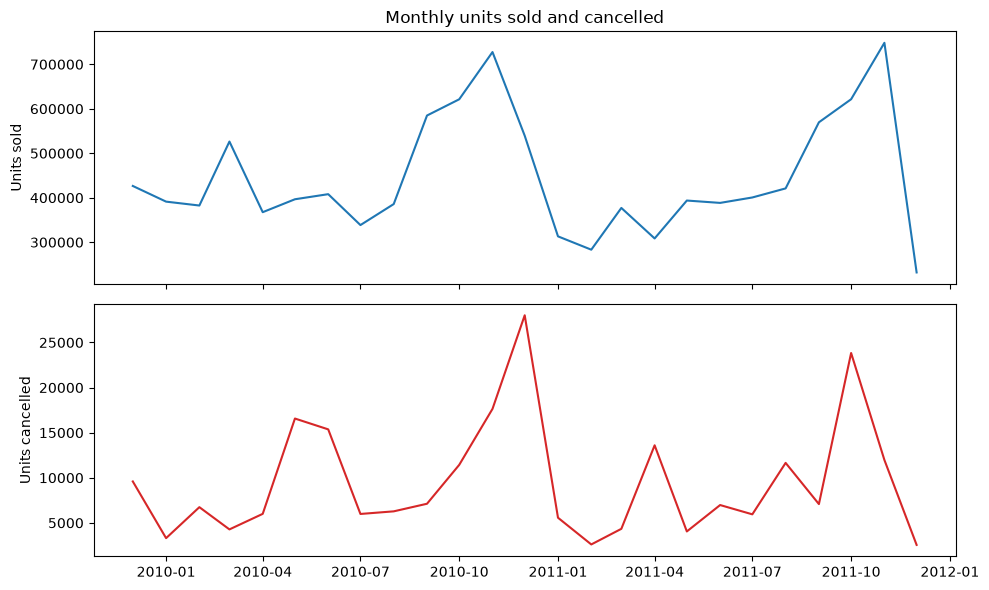

In [72]:
import matplotlib.pyplot as plt

big = ["23843", "23166"]   # the two giant order-and-cancel items, still excluded

def monthly(d):
    m = pd.to_datetime(d["InvoiceDate"]).dt.to_period("M").dt.to_timestamp()
    return d.groupby(m)["Quantity"].sum()

sold_m = monthly(df_sold[~df_sold["StockCode"].isin(big)])
canc_m = -monthly(df_cancelled[~df_cancelled["StockCode"].isin(big)])

fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
a1.plot(sold_m.index, sold_m.values)
a1.set_ylabel("Units sold")
a2.plot(canc_m.index, canc_m.values, color="tab:red")
a2.set_ylabel("Units cancelled")
a1.set_title("Monthly units sold and cancelled")
plt.tight_layout()
plt.show()

## LogReg for items_f

In [82]:
import numpy as np
import statsmodels.api as sm

big = ["23843", "23166"]                      # the two giant order-and-cancel items
m = items_f.drop(index=big, errors="ignore").copy()
m = m[m["avg_price"] > 0]

m["sold"] = m["units_sold"].round().astype(int)
m["canc"] = m["units_cancelled"].clip(upper=m["units_sold"]).round().astype(int)

X = pd.DataFrame({
    "log2_price": np.log2(m["avg_price"]),
    "xmas_share": m["xmas_share"],
    "log2_median_qty": np.log2(m["median_qty"]),
})
X = sm.add_constant(X)

y = np.column_stack([m["canc"], m["sold"] - m["canc"]])   # cancelled vs not cancelled units
model = sm.GLM(y, X, family=sm.families.Binomial()).fit(cov_type="HC1")
print(model.summary())

odds = np.exp(model.params).to_frame("odds_ratio")
odds[["ci_low", "ci_high"]] = np.exp(model.conf_int())
odds

                 Generalized Linear Model Regression Results                  
Dep. Variable:           ['y1', 'y2']   No. Observations:                 3035
Model:                            GLM   Df Residuals:                     3031
Model Family:                Binomial   Df Model:                            3
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -2.2698e+05
Date:                Sat, 31 Oct 2026   Deviance:                   4.4240e+05
Time:                        10:58:38   Pearson chi2:                 9.78e+05
No. Iterations:                     8   Pseudo R-squ. (CS):              1.000
Covariance Type:                  HC1                                         
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
const              -4.9816      0.476    -

,odds_ratio,ci_low,ci_high
const,0.006863,0.002701,0.017439
log2_price,1.422154,1.197156,1.689437
xmas_share,3.037938,0.680274,13.566685
log2_median_qty,1.192374,0.996070,1.427364


                 multiplier  range_low  range_high  p_value
log2_price            1.422      1.197       1.689    0.000
xmas_share            3.038      0.680      13.567    0.146
log2_median_qty       1.192      0.996       1.427    0.055


In [76]:
big = ["23843", "23166"]
m = items_f.drop(index=big, errors="ignore")
m = m[(m["cancel_rate"] > 0) & (m["avg_price"] > 0)]

X = pd.DataFrame({
    "ln_price": np.log(m["avg_price"]),
    "xmas_share": m["xmas_share"],
    "ln_median_qty": np.log(m["median_qty"]),
})
ols = sm.OLS(np.log(m["cancel_rate"]), sm.add_constant(X)).fit(cov_type="HC3")
ols.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            cancel_rate   R-squared:                       0.039
Model:                            OLS   Adj. R-squared:                  0.038
Method:                 Least Squares   F-statistic:                     27.25
Date:                Sat, 31 Oct 2026   Prob (F-statistic):           2.56e-17
Time:                        10:49:52   Log-Likelihood:                -3978.6
No. Observations:                2318   AIC:                             7965.
Df Residuals:                    2314   BIC:                             7988.
Df Model:                           3                                         
Covariance Type:                  HC3                                         
=================================================================================
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
const            -5.1517      0.104    -49.451      0.000      -5.356      -4.947
ln_price          0.3715      0.044      8.494      0.000       0.286       0.457
xmas_share        0.2586      0.141      1.834      0.067      -0.018       0.535
ln_median_qty     0.2070      0.049      4.255      0.000       0.112       0.302
==============================================================================
Omnibus:                        8.816   Durbin-Watson:                   1.706
Prob(Omnibus):                  0.012   Jarque-Bera (JB):                9.627
Skew:                          -0.098   Prob(JB):                      0.00812
Kurtosis:                       3.247   Cond. No.                         9.53
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity robust (HC3)
"""